## 1. Setup
Import the libraries needed for this notebook.

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

plt.style.use("default")
sns.set_style("whitegrid")

## 2. EDA Helper Functions
Reusable functions used to explore the dataset.

In [ ]:
# Dataset Overview
def dataset_overview(df):
    """
    Displays basic information about the dataset.
    """

    print("=" * 80)
    print("DATASET OVERVIEW")
    print("=" * 80)

    print(f"\nRows                : {df.shape[0]}")
    print(f"Columns             : {df.shape[1]}")

    print("\nColumn Names")
    print("-" * 80)

    for col in df.columns:
        print(col)

    print("\nDataset Info")
    print("-" * 80)
    print(df.info())

    print("\nStatistical Summary (Numerical)")
    print("-" * 80)
    print(df.describe().T)

    print("\nStatistical Summary (Categorical)")
    print("-" * 80)
    print(df.describe(include="object").T)

  # Column Analysis

def column_analysis(df):
    """
    Displays metadata for every column.
    """

    print("\n")
    print("=" * 80)
    print("COLUMN ANALYSIS")
    print("=" * 80)

    total_rows = len(df)

    for col in df.columns:

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        dtype = df[col].dtype
        missing = df[col].isna().sum()
        unique = df[col].nunique(dropna=True)

        print(f"Data Type          : {dtype}")
        if unique <= 20:
            print(df[col].unique())
        else:
            print(df[col].unique()[:20])
            print(f"\nshowing first 20 of {unique} unique values")

        if unique >= 0.95 * total_rows:
            print("Possible Identifier Column")
# Missing Value Analysis
def missing_value_analysis(df):
    print("\n")
    print("=" * 80)
    print("MISSING VALUE ANALYSIS")
    print("=" * 80)

    missing = df.isnull().sum()

    missing_percent = (missing / len(df)) * 100

    missing_df = pd.DataFrame({

        "Missing Count": missing,
        "Missing Percentage": missing_percent

    })

    print(missing_df)
    """
    # Heatmap
    plt.figure(figsize=(12,6))
    sns.heatmap(df.isnull(),cbar=True,cmap="viridis")
    plt.title("Missing Value Heatmap")
    plt.show()"""

    #Bar Chart
    plt.figure(figsize=(12,5))
    missing_percent.plot(kind="bar")
    plt.ylabel("Missing Percentage")
    plt.title("Missing Values (%)")
    plt.xticks(rotation=90)
    plt.show()

# Duplicate values analysis
def duplicate_analysis(df):
    """
    Displays duplicate row statistics.
    """

    print("\n")
    print("=" * 80)
    print("DUPLICATE ANALYSIS")
    print("=" * 80)

    duplicates = df.duplicated().sum()

    duplicate_percent = (duplicates / len(df)) * 100

    print(f"Duplicate Rows       : {duplicates}")

    print(f"Duplicate Percentage : {duplicate_percent:.2f}%")

    plt.figure(figsize=(4,4))

    plt.pie(

        [len(df)-duplicates, duplicates],

        labels=["Unique Rows", "Duplicate Rows"],

        autopct="%1.1f%%"

    )

    plt.title("Duplicate Row Distribution")

    plt.show()
# Numerical and Categorical analysis
from scipy import stats

def numerical_analysis(df):
    """
    Performs analysis on all numerical columns.
    """

    print("\n")
    print("=" * 80)
    print("NUMERICAL FEATURE ANALYSIS")
    print("=" * 80)

    for col in df.columns:

        # --------------------------------------------
        # Numeric column OR object storing numbers
        # --------------------------------------------

        if pd.api.types.is_numeric_dtype(df[col]):
            temp = df[col].dropna()

        else:
            temp = pd.to_numeric(df[col], errors="coerce").dropna()

            if len(temp) < 0.9 * df[col].notna().sum():
                continue

        if temp.empty:
            continue

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        print(f"Mean       : {temp.mean():.3f}")
        print(f"Median     : {temp.median():.3f}")
        print(f"Std Dev    : {temp.std():.3f}")
        print(f"Variance   : {temp.var():.3f}")
        print(f"Skewness   : {temp.skew():.3f}")
        print(f"Kurtosis   : {temp.kurtosis():.3f}")

        # --------------------------
        # Histogram
        # --------------------------

        plt.figure(figsize=(6,4))
        plt.hist(temp,bins=30)

        plt.title(f"Histogram : {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.show()

        # --------------------------
        # Boxplot
        # --------------------------

        plt.figure(figsize=(6,2))
        sns.boxplot(x=temp)

        plt.title(f"Boxplot : {col}")
        plt.show()
        """
        # --------------------------
        # QQ Plot
        # --------------------------

        plt.figure(figsize=(5,5))
        stats.probplot(temp, dist="norm", plot=plt)

        plt.title(f"QQ Plot : {col}")
        plt.show()"""

        # --------------------------
        # Outliers (IQR)
        # --------------------------

        q1 = temp.quantile(0.25)
        q3 = temp.quantile(0.75)

        iqr = q3-q1

        lower = q1 - 1.5*iqr
        upper = q3 + 1.5*iqr

        outliers = ((temp<lower) | (temp>upper)).sum()

        print(f"Outliers Detected : {outliers}")

def categorical_analysis(df):
    """
    Performs analysis on categorical columns.
    """

    print("\n")
    print("=" * 80)
    print("CATEGORICAL FEATURE ANALYSIS")
    print("=" * 80)
    total_rows=len(df.columns)
    for col in df.columns:

        if pd.api.types.is_numeric_dtype(df[col]):
            continue

        temp = pd.to_numeric(df[col], errors="coerce")

        if temp.notna().sum() >= 0.9 * df[col].notna().sum():
            continue

        unique = df[col].nunique(dropna=True)

        print("\n" + "-"*80)
        print(f"Column : {col}")
        print("-"*80)

        print(f"Unique Categories : {unique}")

        counts = df[col].value_counts(dropna=False)
        if unique < 0.80 * total_rows:
          if unique <= 20:
              print(counts)
          else:
              print(counts.head(20))
              print(f"\nShowing Top 20 categories out of {unique}")

          plt.figure(figsize=(8,4))

          counts.plot(kind="bar")

          plt.title(col)
          plt.ylabel("Count")
          plt.xticks(rotation=45)

          plt.show()

def correlation_analysis(df):
    """
    Correlation analysis of numerical columns.
    """

    print("\n")
    print("=" * 80)
    print("CORRELATION ANALYSIS")
    print("=" * 80)

    numeric_df = df.select_dtypes(include=np.number)

    if numeric_df.shape[1] < 2:
        print("Not enough numerical columns.")
        return []

    corr = numeric_df.corr()

    plt.figure(figsize=(10,8))

    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.show()

    print("\nHighly Correlated Feature Pairs")

    high_corr=[]

    cols=corr.columns

    for i in range(len(cols)):
        for j in range(i+1,len(cols)):

            if abs(corr.iloc[i,j])>=0.8:

                print(f"{cols[i]}, {cols[j]} = {corr.iloc[i,j]}")

                high_corr.append((cols[i],cols[j],corr.iloc[i,j]))

    return high_corr

def target_analysis(df,task,target):

    print("\n")
    print("="*80)
    print("TARGET ANALYSIS")
    print("="*80)

    if target is None:
        print("No target provided as parameter!")
        return

    if task.lower()=="classification":

        print(df[target].value_counts())

        plt.figure(figsize=(6,4))

        df[target].value_counts().plot(kind="bar")

        plt.title("Class Distribution")

        plt.show()

    elif task.lower()=="regression":

        print(df[target].describe())

        plt.figure(figsize=(6,4))

        plt.hist(df[target].dropna(),bins=30)

        plt.title("Target Distribution")

        plt.show()

def eda_summary(df, high_corr):

    print("\n")
    print("="*80)
    print("FINAL EDA SUMMARY")
    print("="*80)

    print(f"Rows                     : {df.shape[0]}")
    print(f"Columns                  : {df.shape[1]}")

    print(f"Numerical Columns        : {len(df.select_dtypes(include=np.number).columns)}")

    print(f"Categorical Columns      : {len(df.select_dtypes(exclude=np.number).columns)}")

    print(f"Duplicate Rows           : {df.duplicated().sum()}")

    print(f"Columns with Missing     : {(df.isnull().sum()>0).sum()}")

    print(f"Highly Correlated Pairs  : {len(high_corr)}")

    print("\nEDA Completed Successfully.")



In [ ]:
def tabular_eda(df, task, target=None):

    dataset_overview(df)

    column_analysis(df)

    missing_value_analysis(df)

    duplicate_analysis(df)

    numerical_analysis(df)

    categorical_analysis(df)

    high_corr = correlation_analysis(df)

    target_analysis(df, task, target)

    eda_summary(df, high_corr)

## 3. Load Dataset

In [ ]:
iris=pd.read_csv("datasets\iris\Iris.csv")

## 4. Exploratory Data Analysis

DATASET OVERVIEW

Rows                : 150
Columns             : 6

Column Names
--------------------------------------------------------------------------------
Id
SepalLengthCm
SepalWidthCm
PetalLengthCm
PetalWidthCm
Species

Dataset Info
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None

Statistical Summary (Numerical)
--------------------------------------------------------------------------------
               count       mean        s

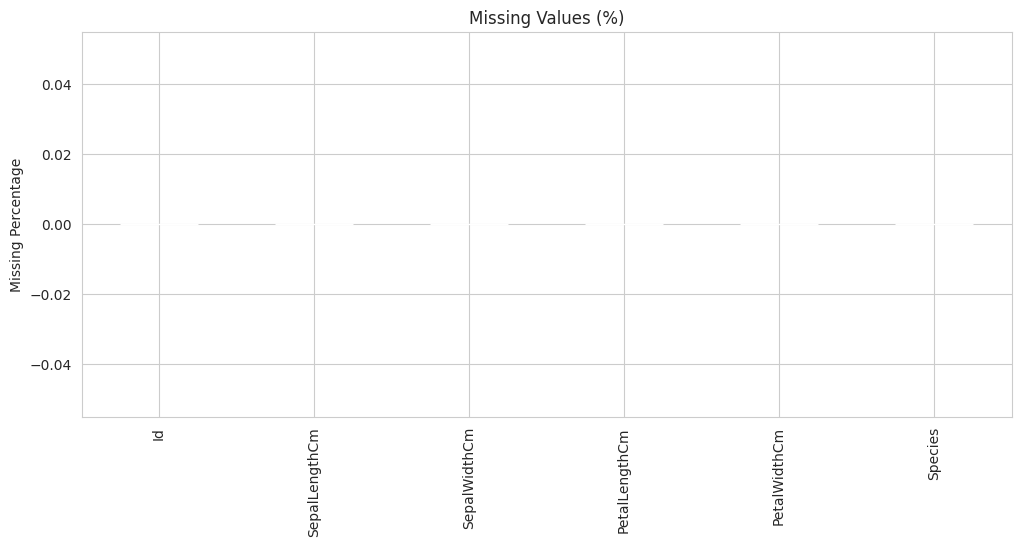



DUPLICATE ANALYSIS
Duplicate Rows       : 0
Duplicate Percentage : 0.00%


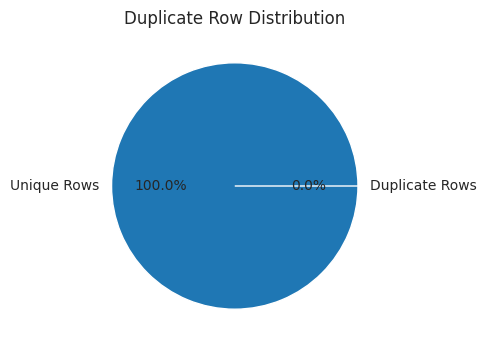



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Id
--------------------------------------------------------------------------------
Mean       : 75.500
Median     : 75.500
Std Dev    : 43.445
Variance   : 1887.500
Skewness   : 0.000
Kurtosis   : -1.200


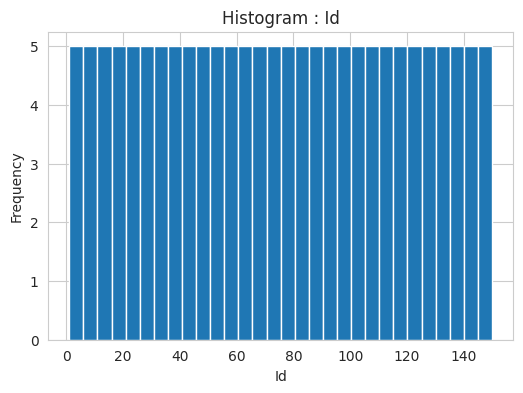

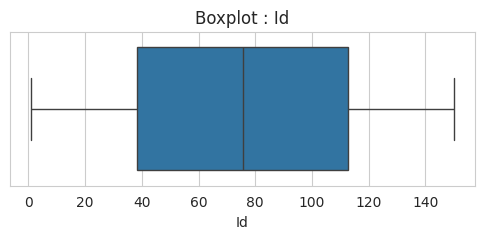

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : SepalLengthCm
--------------------------------------------------------------------------------
Mean       : 5.843
Median     : 5.800
Std Dev    : 0.828
Variance   : 0.686
Skewness   : 0.315
Kurtosis   : -0.552


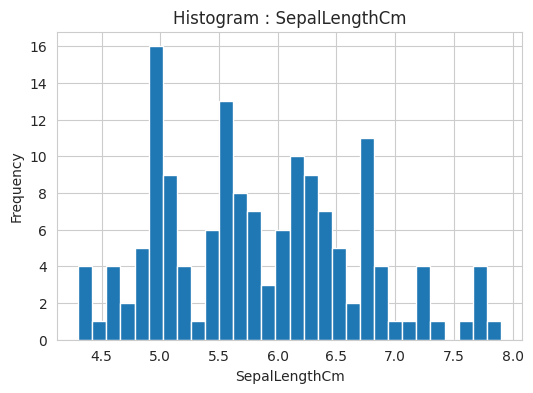

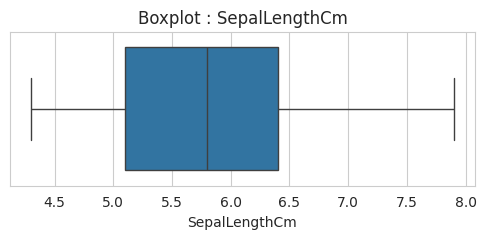

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : SepalWidthCm
--------------------------------------------------------------------------------
Mean       : 3.054
Median     : 3.000
Std Dev    : 0.434
Variance   : 0.188
Skewness   : 0.334
Kurtosis   : 0.291


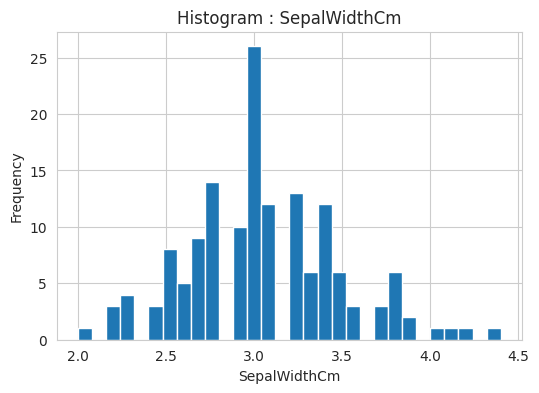

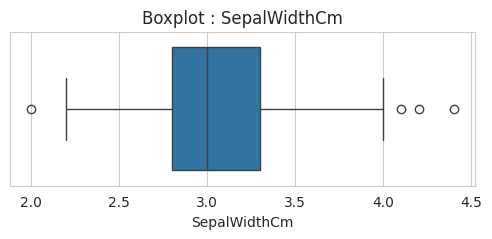

Outliers Detected : 4

--------------------------------------------------------------------------------
Column : PetalLengthCm
--------------------------------------------------------------------------------
Mean       : 3.759
Median     : 4.350
Std Dev    : 1.764
Variance   : 3.113
Skewness   : -0.274
Kurtosis   : -1.402


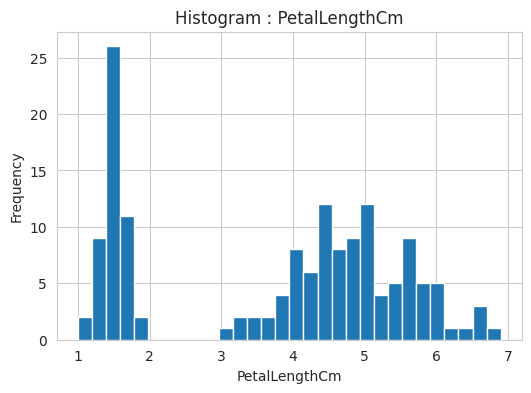

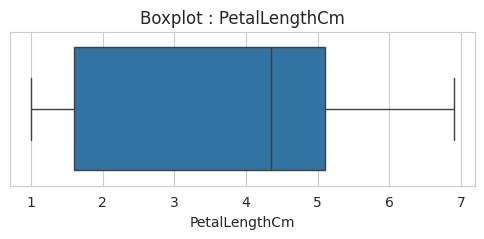

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : PetalWidthCm
--------------------------------------------------------------------------------
Mean       : 1.199
Median     : 1.300
Std Dev    : 0.763
Variance   : 0.582
Skewness   : -0.105
Kurtosis   : -1.340


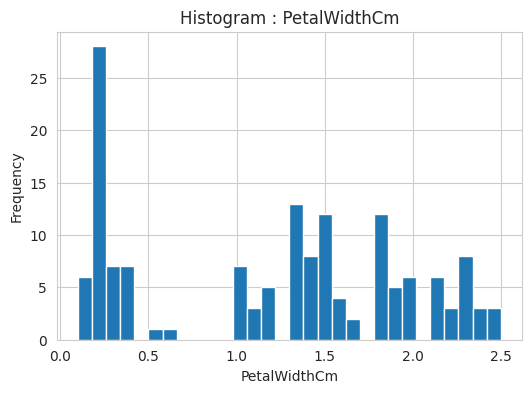

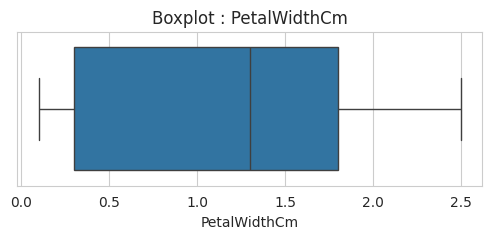

Outliers Detected : 0


CATEGORICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Species
--------------------------------------------------------------------------------
Unique Categories : 3
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


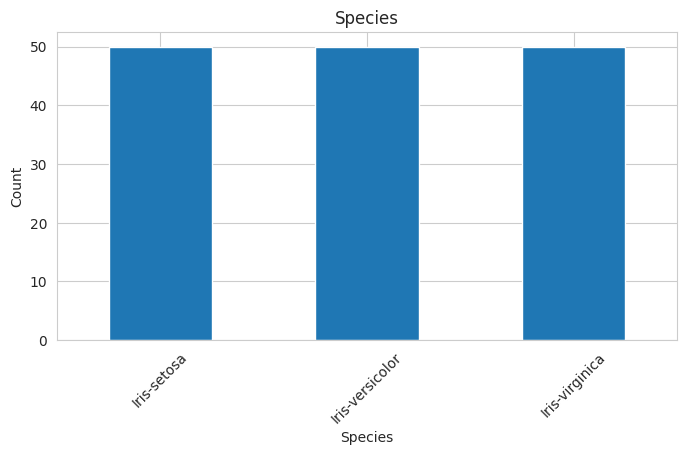



CORRELATION ANALYSIS


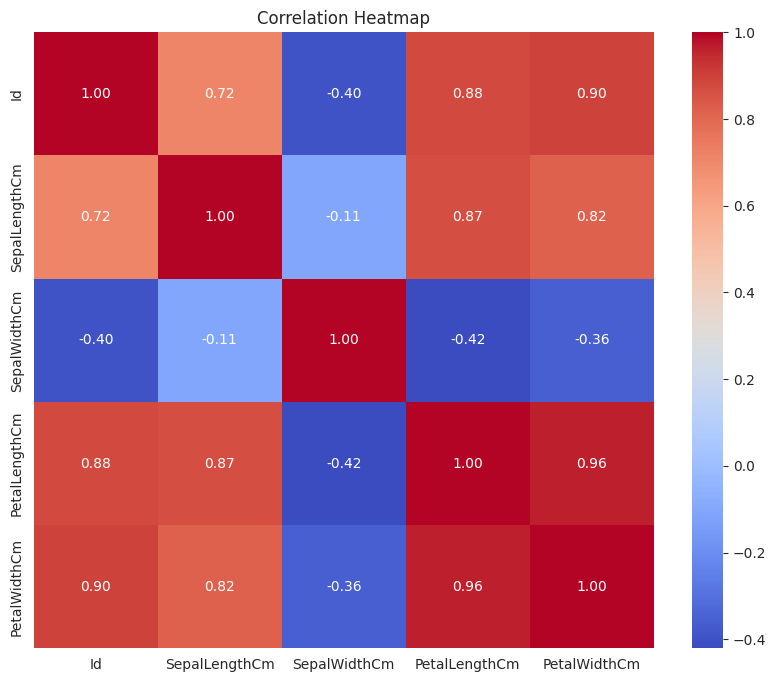


Highly Correlated Feature Pairs
Id, PetalLengthCm = 0.8827473181390557
Id, PetalWidthCm = 0.8997585770933499
SepalLengthCm, PetalLengthCm = 0.8717541573048716
SepalLengthCm, PetalWidthCm = 0.8179536333691642
PetalLengthCm, PetalWidthCm = 0.9627570970509662


TARGET ANALYSIS
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


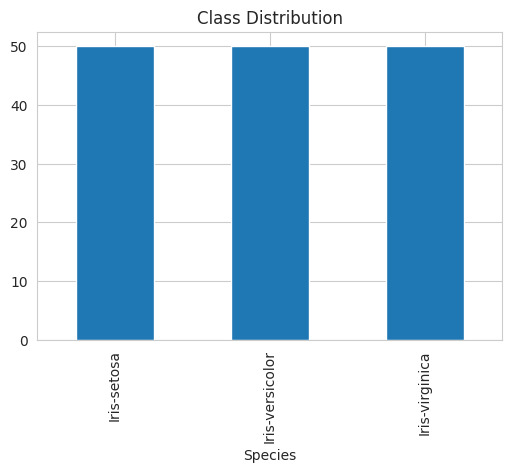



FINAL EDA SUMMARY
Rows                     : 150
Columns                  : 6
Numerical Columns        : 5
Categorical Columns      : 1
Duplicate Rows           : 0
Columns with Missing     : 0
Highly Correlated Pairs  : 5

EDA Completed Successfully.


In [ ]:
tabular_eda(iris,"classification","Species")

In [ ]:
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 5. Data Preprocessing
Drop the identifier column, encode the target labels, and separate features from the target.

In [ ]:
iris = iris.drop("Id", axis=1)

In [ ]:
iris.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

iris["Species"] = encoder.fit_transform(iris["Species"])

In [ ]:
X = iris.drop("Species", axis=1)

y = iris["Species"]

## 6. Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.2,

    random_state=42,

    stratify=y

)

## 7. Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

## 8. Model Training

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

## 9. Model Evaluation

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

Logistic Regression Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



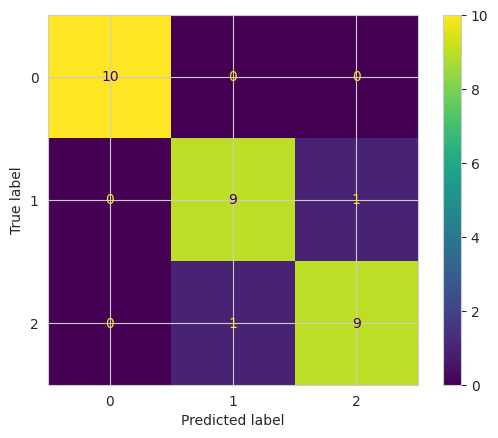

In [ ]:
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))

print(classification_report(y_test, y_pred_lr))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr)

plt.show()